**Part 1**

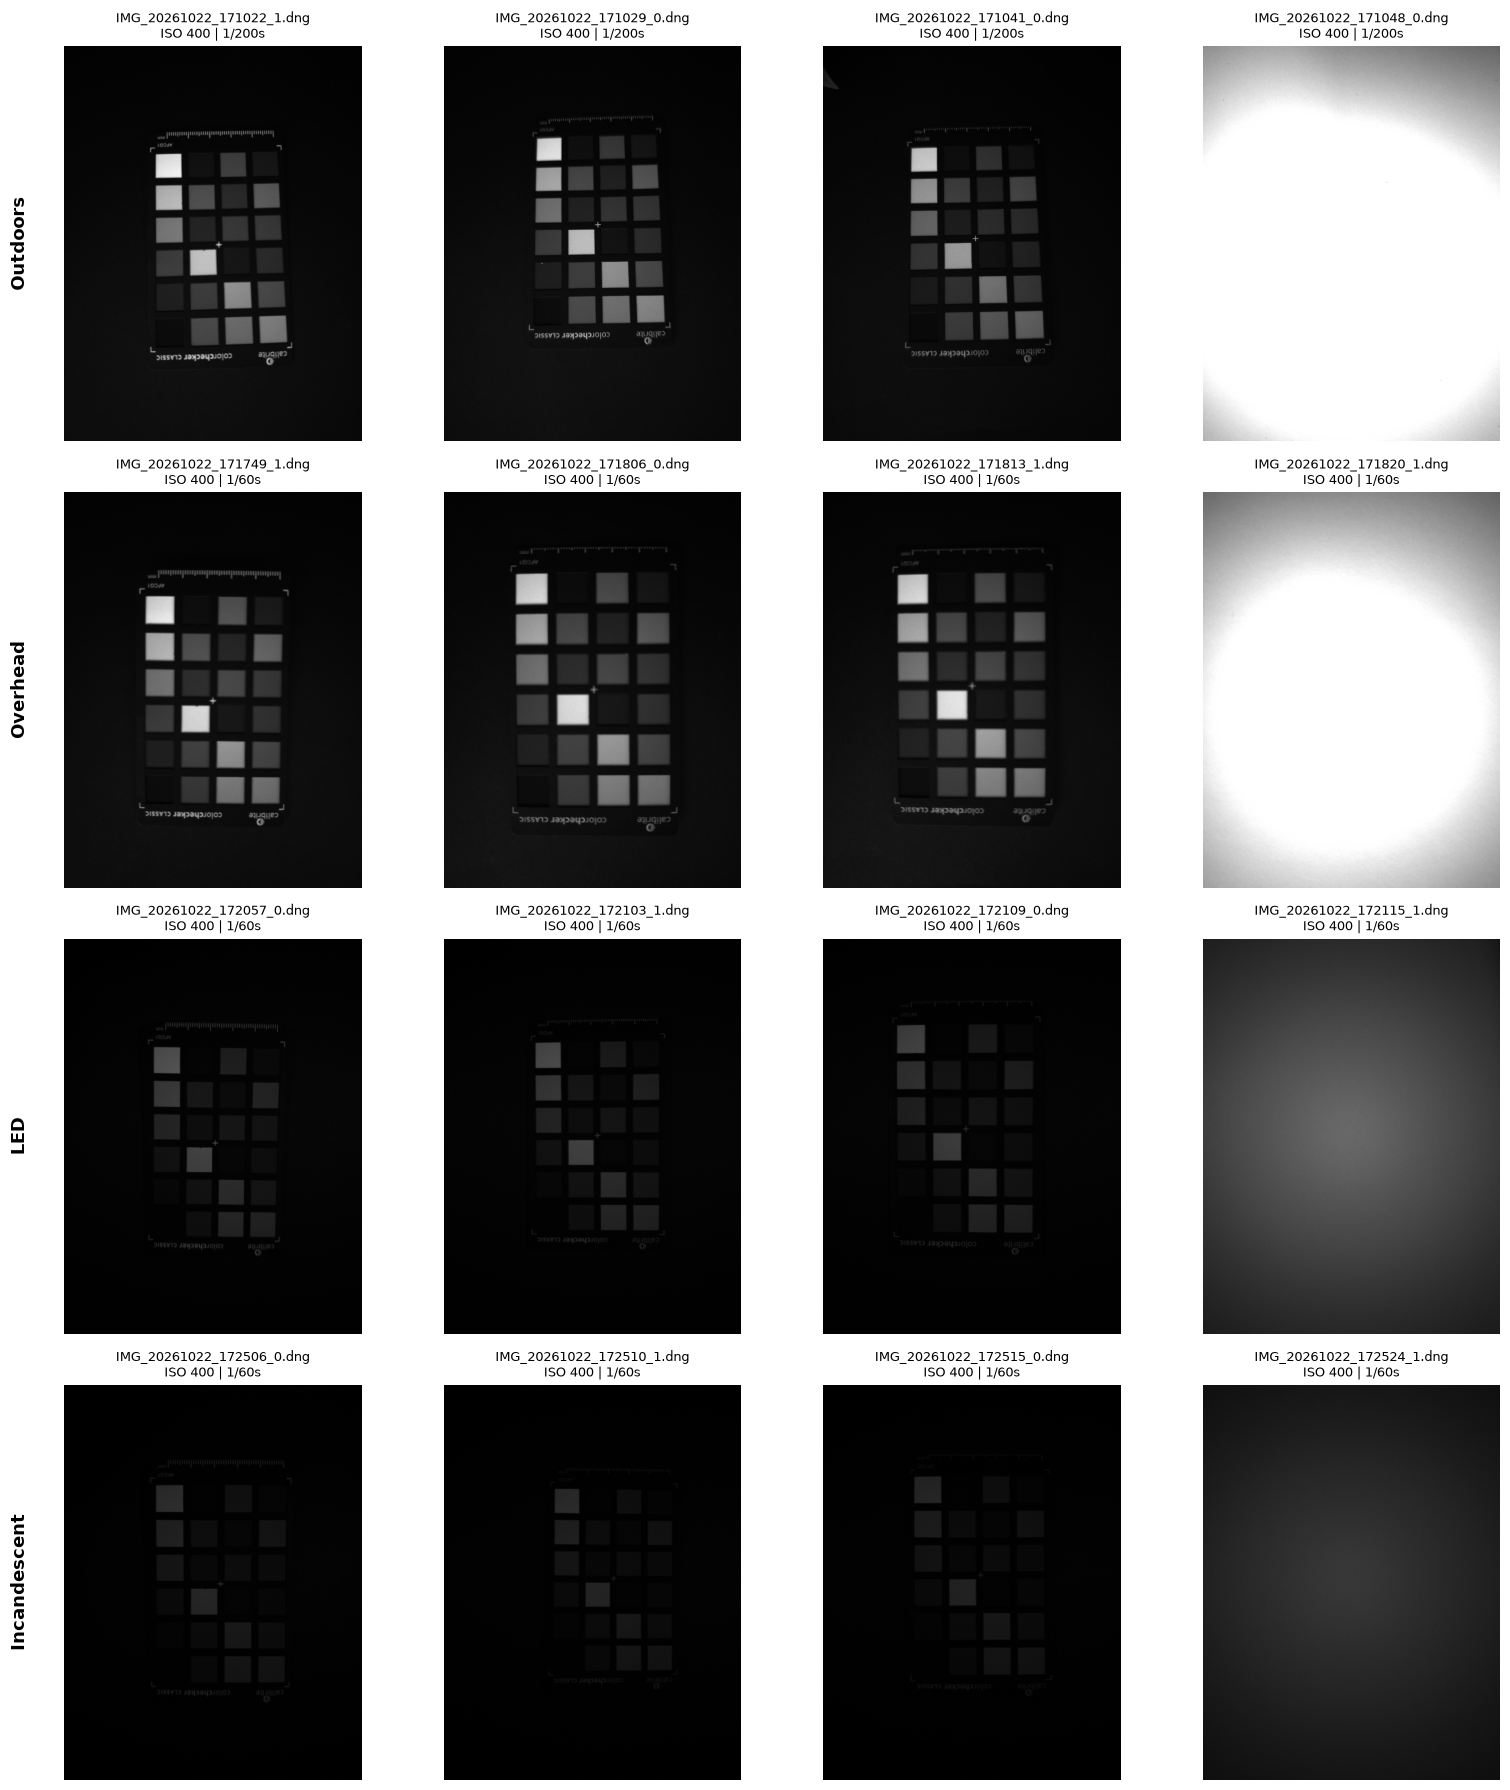

In [2]:
#contact sheet with round, chart, ISO, exposure
import glob
import math
import os
import matplotlib.pyplot as plt
import numpy as np
import rawpy
import tifffile

ISO_TAG, EXPOSURE_TAG = 34855, 33434


def get_exif_info(path):
    """Extracts ISO and exposure time (seconds) using tifffile."""
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = (
            p.tags["ExifTag"].value
            if "ExifTag" in p.tags
            else {tag.code: tag.value for tag in p.tags.values()}
        )
        iso = exif.get(ISO_TAG) or exif.get("ISOSpeedRatings")
        if isinstance(iso, (tuple, list)):
            iso = iso[0]

        exp = exif.get(EXPOSURE_TAG) or exif.get("ExposureTime")
        if isinstance(exp, (tuple, list)) and len(exp) == 2:
            exp_sec = exp[0] / exp[1] if exp[1] != 0 else 0.0
        else:
            exp_sec = float(exp) if exp else 0.0

        return int(iso) if iso else None, exp_sec


def fmt_exp(sec):
    """Formats exposure seconds into a clean shutter speed string."""
    if sec <= 0:
        return "0s"
    return f"1/{round(1.0 / sec)}s" if sec < 1.0 else f"{round(sec, 2)}s"


# --- 1. Scan and strictly filter for DNG files (Alphabetically Sorted) ---
color_dir = "../color_captures/"
files = sorted([
    f
    for f in glob.glob(os.path.join(color_dir, "*"))
    if f.lower().endswith(".dng")
])

row_labels = ["Outdoors", "Overhead", "LED", "Incandescent"]

if not files:
    print(f"No DNG files found in '{color_dir}'.")
else:
    num_files = len(files)
    cols = 4
    rows = len(row_labels)  # 4 rows corresponding to the 4 illuminant rounds

    fig, axes = plt.subplots(rows, cols, figsize=(16, 4.5 * rows))

    for idx, path in enumerate(files):
        r = idx // cols
        c = idx % cols

        if r >= rows:
            break  # In case there are more than 16 files

        ax = axes[r, c] if rows > 1 else axes[c]

        iso, exp_sec = get_exif_info(path)
        iso_str = f"ISO {iso}" if iso else "ISO N/A"
        exp_str = fmt_exp(exp_sec)

        with rawpy.imread(path) as raw:
            # Read raw image array and subsample for speed
            raw_data = raw.raw_image.astype(np.float32)
            raw_thumb = raw_data[::4, ::4]

            # Ensure vertical orientation (Portrait: height > width)
            if raw_thumb.shape[1] > raw_thumb.shape[0]:
                raw_thumb = np.rot90(raw_thumb)

            black = raw.black_level_per_channel[0]
            white = raw.white_level
            raw_norm = np.clip((raw_thumb - black) / (white - black), 0, 1)

            ax.imshow(raw_norm, cmap="gray", vmin=0, vmax=1)
            ax.set_title(
                f"{os.path.basename(path)}\n{iso_str} | {exp_str}",
                fontsize=9,
            )
            ax.axis("off")

            # Add row label on the far left column
            if c == 0:
                ax.text(
                    -0.12,
                    0.5,
                    row_labels[r],
                    transform=ax.transAxes,
                    fontsize=13,
                    fontweight="bold",
                    va="center",
                    ha="right",
                    rotation=90,
                )

    # Hide any unused subplots
    for idx in range(num_files, rows * cols):
        r = idx // cols
        c = idx % cols
        ax = axes[r, c] if rows > 1 else axes[c]
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [3]:
#assert camera ID and confirm bayer
import glob
import os
import tifffile

# Standard numeric EXIF and TIFF tag IDs
MODEL_ID = 272  # Root TIFF tag for Device Model
FOCAL_LENGTH_ID = 37386  # Focal length tag
FOCAL_35MM_ID = 41989  # 35mm equivalent tag
F_NUMBER_ID = 33437  # F-Number tag
ISO_ID = 34855  # ISO speed ratings tag
EXPOSURE_TIME_ID = 33434  # Exposure time (shutter speed) tag
SUBJECT_DISTANCE_ID = 37382  # Subject distance (focus) tag


def format_shutter_speed(exp_time):
  """Converts exposure time into a clean 1/# format for sub-second values."""
  if not exp_time:
    return "Unknown"

  # Handle EXIF rational tuple (numerator, denominator)
  if isinstance(exp_time, (tuple, list)) and len(exp_time) == 2:
    num, den = exp_time[0], exp_time[1]
    if num == 0 or den == 0:
      return "0s"
    val = num / den
  elif isinstance(exp_time, (int, float)):
    val = float(exp_time)
  else:
    return str(exp_time)

  # Format as 1/# if less than 1 second, otherwise show standard seconds
  if val >= 1.0:
    return f"{round(val, 2)}s"
  else:
    # Calculate the reciprocal denominator for 1/# format
    reciprocal = (
        round(den / num)
        if (isinstance(exp_time, (tuple, list)) and num != 0)
        else round(1.0 / val)
    )
    return f"1/{reciprocal}s"


def lens_id(path):
  """The fingerprint of the camera and capture settings that made this raw file."""
  with tifffile.TiffFile(path) as t:
    p = t.pages[0]

    # 1. Extract Device Model from root TIFF tags safely
    device_model = p.tags.get(MODEL_ID)
    if device_model:
      device_model = device_model.value
      if isinstance(device_model, bytes):
        device_model = (
            device_model.decode("utf-8", errors="ignore").strip()
        )
    else:
      device_model = "Google Pixel"

    # Extract metadata directory for sub-IFD tags
    if "ExifTag" in p.tags:
      exif = p.tags["ExifTag"].value
    else:
      exif = {tag.code: tag.value for tag in p.tags.values()}

    # 2. Extract Focal Length
    fl = exif.get(FOCAL_LENGTH_ID) or exif.get("FocalLength")
    if fl and isinstance(fl, (tuple, list)) and len(fl) == 2:
      calculated_fl = round(fl[0] / fl[1], 3)
    else:
      calculated_fl = fl if fl else 0.0

    # 3. Extract Aperture / F-Number
    f_num = exif.get(F_NUMBER_ID) or exif.get("FNumber")
    if f_num and isinstance(f_num, (tuple, list)) and len(f_num) == 2:
      calculated_f = round(f_num[0] / f_num[1], 2)
    else:
      calculated_f = f_num if f_num else None

    # 4. Extract 35mm Equivalent
    focal_35mm = exif.get(FOCAL_35MM_ID) or exif.get(
        "FocalLengthIn35mmFilm", None
    )

    # 5. Extract ISO
    iso_val = (
        exif.get(ISO_ID)
        or exif.get("ISOSpeedRatings")
        or exif.get("PhotographicSensitivity")
    )
    if isinstance(iso_val, (tuple, list)):
      iso_val = iso_val[0]
    iso = int(iso_val) if iso_val is not None else None

    # 6. Extract Shutter Speed (Exposure Time)
    raw_exp = exif.get(EXPOSURE_TIME_ID) or exif.get("ExposureTime")
    calculated_exp = format_shutter_speed(raw_exp)

    # 7. Extract Focus Distance (Subject Distance)
    focus_dist = exif.get(SUBJECT_DISTANCE_ID) or exif.get("SubjectDistance")
    if focus_dist and isinstance(focus_dist, (tuple, list)) and len(focus_dist) == 2:
      calculated_focus = round(focus_dist[0] / focus_dist[1], 2)
    else:
      calculated_focus = focus_dist if focus_dist else "Unknown/Inf"

    # 8. Dimensions
    width = p.tags["ImageWidth"].value
    length = p.tags["ImageLength"].value

    return (
        device_model,
        calculated_fl,
        calculated_f,
        focal_35mm,
        (width, length),
        iso,
        calculated_exp,
        calculated_focus,
    )


# --- Directory and File Scanning ---
flat_dir = "../color_captures/"  # Target directory for your flat field captures
valid_paths = sorted([
    f
    for f in glob.glob(os.path.join(flat_dir, "*"))
    if f.lower().endswith(".dng")
])

if not valid_paths:
  print(f"Error: No DNG files found in directory '{flat_dir}'.")
else:
  models = set()
  focals = set()
  f_stops = set()
  focal_35s = set()
  shapes = set()
  isos = set()
  shutters = set()
  focuses = set()

  print(f"Scanning {len(valid_paths)} DNG file(s) in '{flat_dir}'...\n")

  for p in valid_paths:
    fp = lens_id(p)
    models.add(fp[0])
    focals.add(fp[1])
    f_stops.add(fp[2])
    focal_35s.add(fp[3])
    shapes.add(fp[4])
    isos.add(fp[5])
    shutters.add(fp[6])  # Collects every unique shutter speed string
    focuses.add(fp[7])

  # --- Print Results and Unique Counts ---
  print("=== Dataset Audit Summary ===")
  print(f"Device Models detected ({len(models)} unique): {models}")
  print(f"Focal Lengths detected ({len(focals)} unique): {focals} mm")
  print(f"F-stops detected ({len(f_stops)} unique): {f_stops}")
  print(f"35mm Equivalents detected ({len(focal_35s)} unique): {focal_35s} mm")
  print(f"Sensor Shapes detected ({len(shapes)} unique): {shapes}")
  print(f"ISOs detected ({len(isos)} unique): {isos}")
  print(f"Shutter Speeds detected ({len(shutters)} unique): {sorted(list(shutters))}")
  #print(f"Focus Distances detected ({len(focuses)} unique): {focuses} m")

  print("\n----------------------------------------")
  # Check if model, focal length, f-stop, 35mm, and sensor shape are identical
  if (
      len(models) == 1
      and len(focals) == 1
      and len(f_stops) == 1
      and len(focal_35s) == 1
      and len(shapes) == 1
  ):
    print(
        f"Passed. There is one lens detected with {len(isos)} ISO(s) and"
        f" {len(shutters)} exposure time(s) detected."
    )
  else:
    print("Multiple camera hardware configurations detected.")
  print("----------------------------------------")

  # --- Assertions ---
  assert (
      len(models) == 1
  ), f"Assertion Failed: Multiple device models found: {models}"
  assert (
      len(isos) == 1
  ), f"Assertion Failed: Multiple ISO values found: {isos}. All flat fields must be captured at a single fixed ISO[cite: 2]!"

Scanning 16 DNG file(s) in '../color_captures/'...

=== Dataset Audit Summary ===
Device Models detected (1 unique): {'Pixel 9'}
Focal Lengths detected (1 unique): {6.9} mm
F-stops detected (1 unique): {1.68}
35mm Equivalents detected (1 unique): {None} mm
Sensor Shapes detected (1 unique): {(4080, 3072)}
ISOs detected (1 unique): {400}
Shutter Speeds detected (2 unique): ['1/200s', '1/60s']

----------------------------------------
Passed. There is one lens detected with 1 ISO(s) and 2 exposure time(s) detected.
----------------------------------------


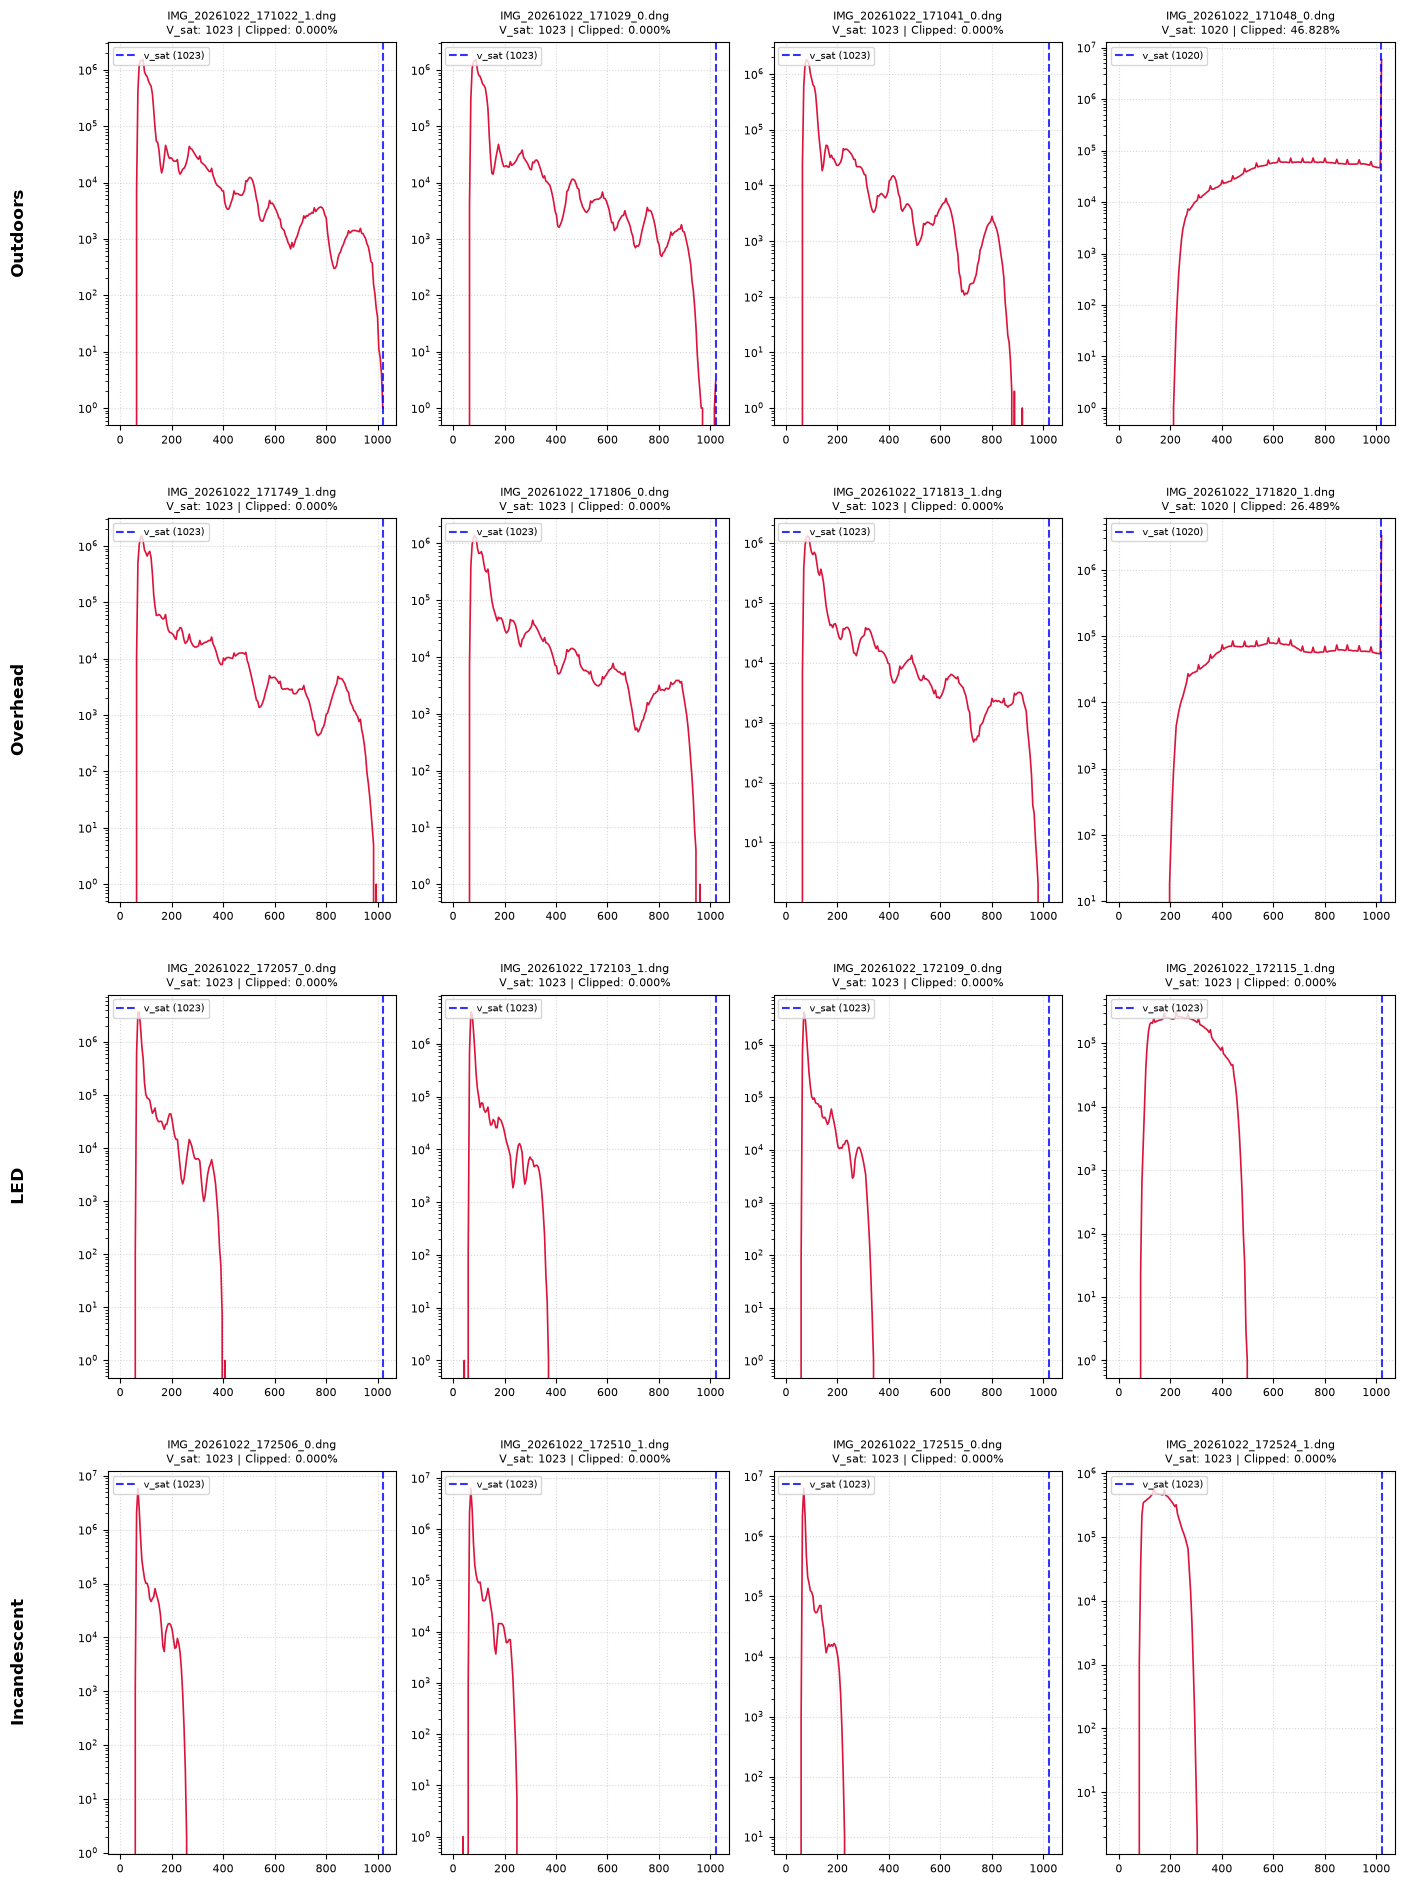

In [4]:
#histogram
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import rawpy

color_dir = "../color_captures/"
files = sorted([
    f for f in glob.glob(os.path.join(color_dir, "*")) if f.lower().endswith(".dng")
])

row_labels = ["Outdoors", "Overhead", "LED", "Incandescent"]

if not files:
    print(f"No DNG files found in '{color_dir}'.")
else:
    cols = 4
    rows = len(row_labels)

    fig, axes = plt.subplots(rows, cols, figsize=(14, 4.8 * rows))

    for idx, path in enumerate(files):
        r = idx // cols
        c = idx % cols

        if r >= rows:
            break

        ax = axes[r, c] if rows > 1 else axes[c]

        # Force vertical (portrait) aspect ratio for the plot container
        ax.set_box_aspect(1.33)

        with rawpy.imread(path) as raw:
            raw_data = raw.raw_image

            # Ensure the DNG raw data array is vertical (height > width)
            if raw_data.shape[1] > raw_data.shape[0]:
                raw_data = np.rot90(raw_data)

            total_pixels = raw_data.size
            declared_white = raw.white_level

            # Compute histogram
            hist, bin_edges = np.histogram(
                raw_data, bins=200, range=(0, declared_white)
            )
            bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

            # Find the rightmost edge of the data distribution (ignoring minor noise tails)
            valid_bins = np.where(hist > 50)[0]
            if len(valid_bins) > 0:
                rightmost_idx = valid_bins[-1]
                edge_val = int(bin_centers[rightmost_idx])
            else:
                edge_val = int(declared_white)

            # Check if this edge represents true hardware saturation/clipping near the top ceiling
            # (i.e., jammed against the high end with a heavy accumulation of pixels)
            is_truly_clipped = (edge_val >= (declared_white - 15)) or (hist[rightmost_idx] > 5000 and edge_val > 800)

            if is_truly_clipped:
                # Empirical V_sat is where the clipping wall occurs
                v_sat = edge_val
                clipped_count = np.sum(raw_data >= (v_sat - 5))
                clipped_fraction = clipped_count / total_pixels
            else:
                # Natural scene roll-off: Frame did NOT saturate.
                # V_sat is the full hardware ceiling (1023), and clipped fraction is strictly 0.0%.
                v_sat = int(declared_white)
                clipped_fraction = 0.0
            # Plot Histogram on log scale
            ax.plot(bin_centers, hist, color="crimson", lw=1.2)
            
            # Add blue dashed line with v_sat label
            ax.axvline(
                v_sat, 
                color="blue", 
                linestyle="--", 
                alpha=0.8, 
                label=f"v_sat ({v_sat})"
            )
            
            ax.set_yscale("log")
            ax.grid(True, linestyle=":", alpha=0.5)
            ax.legend(loc="upper left", fontsize=7)

            # Title with file name, saturation raw value, and clipped fraction
            title_text = (
                f"{os.path.basename(path)}\n"
                f"V_sat: {v_sat} | Clipped: {clipped_fraction * 100:.3f}%"
            )
            ax.set_title(title_text, fontsize=8)
            ax.tick_params(axis="both", labelsize=8)

            # Add row label on the far left column
            if c == 0:
                ax.text(
                    -0.28,
                    0.5,
                    row_labels[r],
                    transform=ax.transAxes,
                    fontsize=12,
                    fontweight="bold",
                    va="center",
                    ha="right",
                    rotation=90,
                )

    # Hide unused subplots if fewer than rows * cols files
    for idx in range(len(files), rows * cols):
        r = idx // cols
        c = idx % cols
        ax = axes[r, c] if rows > 1 else axes[c]
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [5]:
#double check clip ignore
import glob
import os
import numpy as np
import rawpy

color_dir = "../color_captures/"
files = sorted([
    f for f in glob.glob(os.path.join(color_dir, "*")) if f.lower().endswith(".dng")
])

if not files:
    print(f"No DNG files found in '{color_dir}'.")
else:
    print(f"{'Filename':<35} | {'Total Pixels':<12} | {'V_sat':<6} | {'Clipped Pixels':<15}")
    print("-" * 78)

    for path in files:
        with rawpy.imread(path) as raw:
            raw_data = raw.raw_image

            # Ensure the DNG raw data array is vertical (height > width)
            if raw_data.shape[1] > raw_data.shape[0]:
                raw_data = np.rot90(raw_data)

            total_pixels = raw_data.size
            declared_white = raw.white_level

            # Compute histogram
            hist, bin_edges = np.histogram(
                raw_data, bins=200, range=(0, declared_white)
            )
            bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

            # Find the rightmost edge of the data distribution
            valid_bins = np.where(hist > 50)[0]
            if len(valid_bins) > 0:
                rightmost_idx = valid_bins[-1]
                edge_val = int(bin_centers[rightmost_idx])
            else:
                edge_val = int(declared_white)

            # Check if this edge represents true hardware saturation/clipping
            is_truly_clipped = (edge_val >= (declared_white - 15)) or (hist[rightmost_idx] > 5000 and edge_val > 800)

            if is_truly_clipped:
                v_sat = edge_val
                clipped_count = int(np.sum(raw_data >= (v_sat - 5)))
            else:
                v_sat = int(declared_white)
                clipped_count = 0

            filename = os.path.basename(path)
            print(f"{filename:<35} | {total_pixels:<12} | {v_sat:<6} | {clipped_count:<15}")

Filename                            | Total Pixels | V_sat  | Clipped Pixels 
------------------------------------------------------------------------------
IMG_20261022_171022_1.dng           | 12533760     | 1023   | 0              
IMG_20261022_171029_0.dng           | 12533760     | 1023   | 0              
IMG_20261022_171041_0.dng           | 12533760     | 1023   | 0              
IMG_20261022_171048_0.dng           | 12533760     | 1020   | 5869317        
IMG_20261022_171749_1.dng           | 12533760     | 1023   | 0              
IMG_20261022_171806_0.dng           | 12533760     | 1023   | 0              
IMG_20261022_171813_1.dng           | 12533760     | 1023   | 0              
IMG_20261022_171820_1.dng           | 12533760     | 1020   | 3320093        
IMG_20261022_172057_0.dng           | 12533760     | 1023   | 0              
IMG_20261022_172103_1.dng           | 12533760     | 1023   | 0              
IMG_20261022_172109_0.dng           | 12533760     | 1023   | 0

In [6]:
#double check max raw ignore
import glob
import os
import numpy as np
import rawpy

color_dir = "../color_captures/"
files = sorted([
    f for f in glob.glob(os.path.join(color_dir, "*")) if f.lower().endswith(".dng")
])

if not files:
    print(f"No DNG files found in '{color_dir}'.")
else:
    print(f"{'Filename':<35} | {'Declared White Level':<20} | {'Actual Max Raw Value':<20}")
    print("-" * 81)

    for path in files:
        with rawpy.imread(path) as raw:
            raw_data = raw.raw_image

            # Ensure the DNG raw data array is vertical (height > width)
            if raw_data.shape[1] > raw_data.shape[0]:
                raw_data = np.rot90(raw_data)

            declared_white = raw.white_level
            actual_max = raw_data.max()

            filename = os.path.basename(path)
            print(f"{filename:<35} | {declared_white:<20} | {actual_max:<20}")

Filename                            | Declared White Level | Actual Max Raw Value
---------------------------------------------------------------------------------
IMG_20261022_171022_1.dng           | 1023                 | 1020                
IMG_20261022_171029_0.dng           | 1023                 | 1023                
IMG_20261022_171041_0.dng           | 1023                 | 916                 
IMG_20261022_171048_0.dng           | 1023                 | 1023                
IMG_20261022_171749_1.dng           | 1023                 | 993                 
IMG_20261022_171806_0.dng           | 1023                 | 957                 
IMG_20261022_171813_1.dng           | 1023                 | 980                 
IMG_20261022_171820_1.dng           | 1023                 | 1023                
IMG_20261022_172057_0.dng           | 1023                 | 405                 
IMG_20261022_172103_1.dng           | 1023                 | 370                 
IMG_20261022_172

**preprocess**

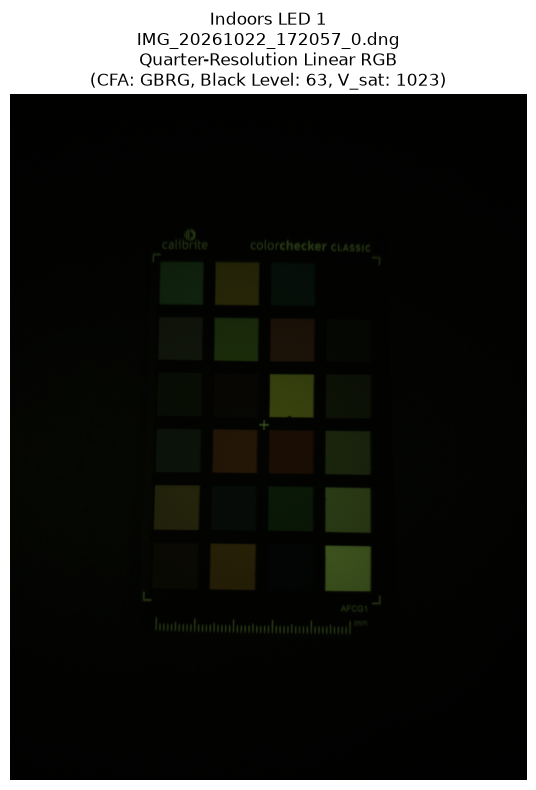

In [ ]:
#raw to linear rgb
import matplotlib.pyplot as plt
import numpy as np
import rawpy


def process_raw_to_linear_rgb(image_path, v_sat_val=1023):
  """Loads a raw DNG file, subtracts black levels, maps GBRG/CFA pattern,

  normalizes to linear RGB, and returns a vertical quarter-resolution RGB
  array.
  """
  with rawpy.imread(image_path) as raw:
    raw_data = raw.raw_image.copy()

    # Ensure even dimensions for 2x2 block reduction
    h, w = raw_data.shape
    h_even = (h // 2) * 2
    w_even = (w // 2) * 2
    raw_data = raw_data[:h_even, :w_even]

    # Metadata extracted from sensor
    cfa_pattern = raw.raw_pattern  # [[3, 2], [0, 1]]
    color_desc = raw.color_desc  # b'RGBG'
    black_levels = raw.black_level_per_channel  # [63, 63, 63, 63]

    r_plane = None
    b_plane = None
    g_planes = []

    # Dynamically map 2x2 sub-planes based on raw_pattern indices
    for r_offset in range(2):
      for c_offset in range(2):
        c_idx = cfa_pattern[r_offset, c_offset]
        c_char = chr(color_desc[c_idx])
        b_level = black_levels[r_offset * 2 + c_offset]

        sub_plane = (
            raw_data[r_offset::2, c_offset::2].astype(np.float32) - b_level
        )

        if c_char == "R":
          r_plane = sub_plane
        elif c_char == "B":
          b_plane = sub_plane
        elif c_char == "G" or c_char == "g":
          g_planes.append(sub_plane)

    # Average the two green sub-planes
    g_plane = np.mean(g_planes, axis=0)

    # Normalize by span from black up to V_sat
    avg_black = np.mean(black_levels)
    span = v_sat_val - avg_black

    r_lin = np.clip(r_plane / span, 0.0, 1.0)
    g_lin = np.clip(g_plane / span, 0.0, 1.0)
    b_lin = np.clip(b_plane / span, 0.0, 1.0)

    # Stack into quarter-resolution RGB image
    quarter_rgb = np.stack([r_lin, g_lin, b_lin], axis=-1)

    # Ensure vertical (portrait) orientation and right-side up
    if quarter_rgb.shape[1] > quarter_rgb.shape[0]:
      quarter_rgb = np.rot90(quarter_rgb, k=1)
    quarter_rgb = np.rot90(quarter_rgb, k=2)

    return quarter_rgb


# --- Use the helper function to make and display the first image ---
image_filename = "IMG_20261022_171749_1.dng"
image_path = f"../color_captures/{image_filename}"

# Call helper function (stored in variable `quarter_rgb`)
quarter_rgb = process_raw_to_linear_rgb(image_path, v_sat_val=1023)

# Display Deliverable
plt.figure(figsize=(6, 8))
plt.imshow(quarter_rgb) 
plt.title(
    f"Indoors LED 1\n{image_filename}\nQuarter-Resolution Linear RGB\n"
    "(CFA: GBRG, Black Level: 63, V_sat: 1023)"
)
plt.axis("off")
plt.tight_layout()
plt.show()

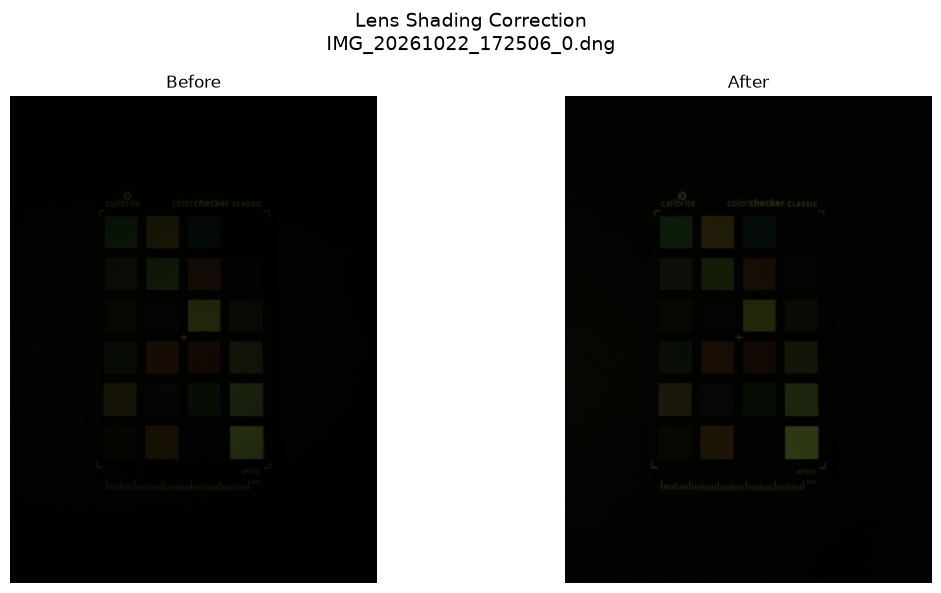

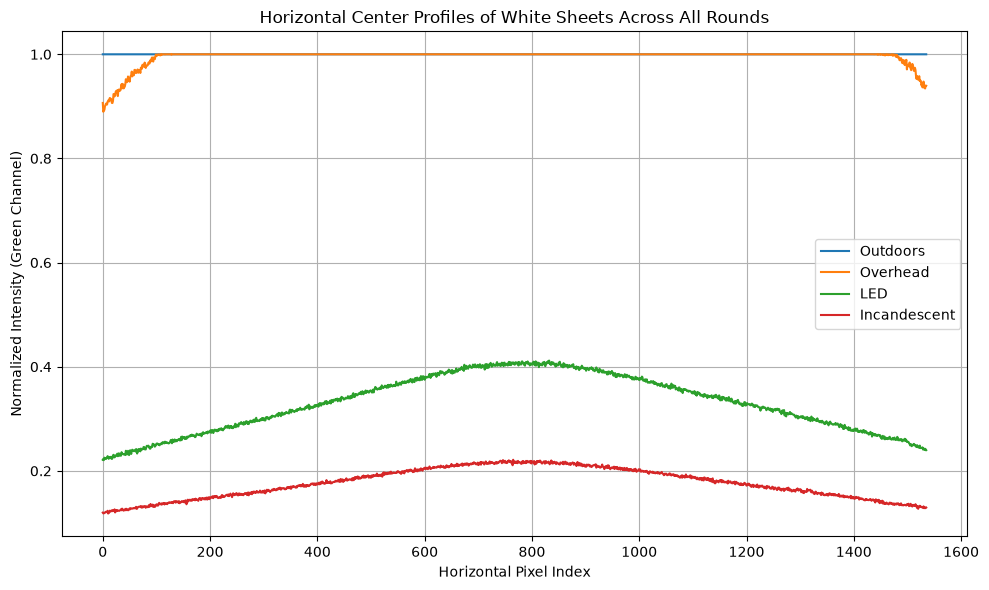


=== DELIVERABLE: Corner-to-Center Ratios Across All White Sheets ===

--- Outdoors Round White Sheet ---
  Red Channel -> Before Ratio: 0.3647 | After Ratio: 1.0000
  Green Channel -> Before Ratio: 0.7308 | After Ratio: 1.0000
  Blue Channel -> Before Ratio: 0.5491 | After Ratio: 1.0000

--- Overhead Round White Sheet ---
  Red Channel -> Before Ratio: 0.3791 | After Ratio: 1.0000
  Green Channel -> Before Ratio: 0.5717 | After Ratio: 1.0000
  Blue Channel -> Before Ratio: 0.3536 | After Ratio: 1.0000

--- LED Round White Sheet ---
  Red Channel -> Before Ratio: 0.2807 | After Ratio: 1.0000
  Green Channel -> Before Ratio: 0.2815 | After Ratio: 1.0000
  Blue Channel -> Before Ratio: 0.2797 | After Ratio: 1.0000

--- Incandescent Round White Sheet ---
  Red Channel -> Before Ratio: 0.2778 | After Ratio: 1.0000
  Green Channel -> Before Ratio: 0.2840 | After Ratio: 1.0000
  Blue Channel -> Before Ratio: 0.2844 | After Ratio: 1.0000


In [104]:
#vignetting correction
import matplotlib.pyplot as plt
import numpy as np
import rawpy

# --- 1. Load Scene Image (from Q2) & White Sheet ---
scene_filename = "IMG_20261022_172506_0.dng"
whitesheet_filename = "IMG_20261022_172524_1.dng"

scene_rgb = process_raw_to_linear_rgb(
    f"../color_captures/{scene_filename}", v_sat_val=1023
)
ws_rgb = process_raw_to_linear_rgb(
    f"../color_captures/{whitesheet_filename}", v_sat_val=1020
)

# --- 2. Channel-Independent Flat-Field Correction on Scene Image ---
hh, ww, _ = scene_rgb.shape
patch_size = 50
r_c, c_c = hh // 2, ww // 2


def get_channel_ratios(ch):
  center_val = np.mean(
      ch[
          r_c - patch_size // 2 : r_c + patch_size // 2,
          c_c - patch_size // 2 : c_c + patch_size // 2,
      ]
  )
  corner_val = np.mean(ch[0:patch_size, 0:patch_size])
  return corner_val / center_val


corrected_channels = []

for i in range(3):
  scene_ch = scene_rgb[:, :, i]
  ws_ch = ws_rgb[:, :, i]

  # Normalize white sheet to its own center independently per channel
  ws_center_val = np.mean(
      ws_ch[
          r_c - patch_size // 2 : r_c + patch_size // 2,
          c_c - patch_size // 2 : c_c + patch_size // 2,
      ]
  )
  ws_ff_norm = ws_ch / ws_center_val

  # Correct scene channel
  corrected_ch = np.clip(scene_ch / ws_ff_norm, 0, 1)
  corrected_channels.append(corrected_ch)

scene_corrected = np.stack(corrected_channels, axis=-1)

# --- 3. Display Before & After Scene Images ---
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(scene_rgb)
axes[0].set_title("Before")
axes[0].axis("off")

axes[1].imshow(scene_corrected)
axes[1].set_title("After")
axes[1].axis("off")

plt.suptitle(f"Lens Shading Correction\n{scene_filename}", fontsize=14)
plt.tight_layout()
plt.show()

# --- 4. Multi-Round Horizontal Profiles & Ratio Calculations Across All White Sheets ---
round_files = {
    "Outdoors": {
        "path": "../color_captures/IMG_20261022_171048_0.dng",
        "v_sat": 1020,
    },
    "Overhead": {
        "path": "../color_captures/IMG_20261022_171820_1.dng",
        "v_sat": 1020,
    },
    "LED": {
        "path": "../color_captures/IMG_20261022_172115_1.dng",
        "v_sat": 1023,
    },
    "Incandescent": {
        "path": "../color_captures/IMG_20261022_172524_1.dng",
        "v_sat": 1023,
    },
}

all_round_ratios = {}

plt.figure(figsize=(10, 6))
for round_name, info in round_files.items():
  # Load each white sheet
  ws_test = process_raw_to_linear_rgb(info["path"], info["v_sat"])

  # Calculate profiles on Green channel
  g_ch = ws_test[:, :, 1]
  profile = np.mean(g_ch[hh // 2 - 5 : hh // 2 + 5, :], axis=0)
  plt.plot(profile, label=round_name)

  # Calculate corner-to-center ratios for all 3 channels on this white sheet
  round_ratios = {"Before": [], "After": []}

  for i in range(3):
    ch = ws_test[:, :, i]

    # 1. Measure Before ratio on the raw white sheet channel
    round_ratios["Before"].append(get_channel_ratios(ch))

    # 2. Compute 2D spatial flat-field normalization for this channel
    center_val = np.mean(
        ch[
            r_c - patch_size // 2 : r_c + patch_size // 2,
            c_c - patch_size // 2 : c_c + patch_size // 2,
        ]
    )
    ws_ff_norm = ch / center_val

    # 3. Apply correction (dividing white sheet by its own flat field)
    ch_corrected = np.clip(ch / ws_ff_norm, 0, 1)

    # 4. Measure After ratio on the corrected white sheet
    round_ratios["After"].append(get_channel_ratios(ch_corrected))

  all_round_ratios[round_name] = round_ratios

plt.title("Horizontal Center Profiles of White Sheets Across All Rounds")
plt.xlabel("Horizontal Pixel Index")
plt.ylabel("Normalized Intensity (Green Channel)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- 5. Print Deliverable Ratios for All White Sheets ---
print(
    "\n=== DELIVERABLE: Corner-to-Center Ratios Across All White Sheets"
    " ==="
)
channels_names = ["Red", "Green", "Blue"]

for round_name, ratios in all_round_ratios.items():
  print(f"\n--- {round_name} Round White Sheet ---")
  for i, ch_name in enumerate(channels_names):
    before = ratios["Before"][i]
    after = ratios["After"][i]
    print(
        f"  {ch_name} Channel -> Before Ratio: {before:.4f} | After Ratio:"
        f" {after:.4f}"
    )

In [ ]:
#sample regions
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np


def extract_colorchecker_manual(
    scene_rgb,
    grid_bbox,  # Pass your eyeballed [ymin, ymax, xmin, xmax] here
    inner_margin=0.25,  # Middle half sampling (50% size) to avoid black borders
    visualize=True,
    title_suffix="",
):
  """Extracts 24 patch means for a portrait ColorChecker (6 rows x 4 columns)

  using a manually specified bounding box.
  """
  ymin, ymax, xmin, xmax = grid_bbox
  num_rows = 6
  num_cols = 4

  row_height = (ymax - ymin) / num_rows
  col_width = (xmax - xmin) / num_cols
  patch_means = []

  if visualize:
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(np.clip(scene_rgb, 0, 1))
    ax.set_title(f"ColorChecker Sampled Regions: {title_suffix}")

  for r in range(num_rows):
    for c in range(num_cols):
      # Exact cell boundaries for this specific patch
      p_ymin = ymin + r * row_height
      p_ymax = ymin + (r + 1) * row_height
      p_xmin = xmin + c * col_width
      p_xmax = xmin + (c + 1) * col_width

      # Sample strictly within the middle half of the patch
      h_len = p_ymax - p_ymin
      w_len = p_xmax - p_xmin

      m_ymin = int(p_ymin + inner_margin * h_len)
      m_ymax = int(p_ymax - inner_margin * h_len)
      m_xmin = int(p_xmin + inner_margin * w_len)
      m_xmax = int(p_xmax - inner_margin * w_len)

      # Extract pixels and compute mean linear RGB
      patch_pixels = scene_rgb[m_ymin:m_ymax, m_xmin:m_xmax, :]
      mean_rgb = np.mean(patch_pixels, axis=(0, 1))
      patch_means.append(mean_rgb)

      if visualize:
        rect = patches.Rectangle(
            (m_xmin, m_ymin),
            m_xmax - m_xmin,
            m_ymax - m_ymin,
            linewidth=1.2,
            edgecolor="cyan",
            facecolor="none",
        )
        ax.add_patch(rect)

  if visualize:
    plt.axis("on")
    plt.tight_layout()
    plt.show()

  return np.array(patch_means)


# --- EXAMPLE USAGE ---
# Plug in your eyeballed coordinates here: [ymin, ymax, xmin, xmax]
my_manual_bbox = [500, 1515, 395, 1070]

patch_means_table = extract_colorchecker_manual(
    scene_rgb=scene_corrected,
    grid_bbox=my_manual_bbox,
    inner_margin=0.25,
    visualize=True,
    title_suffix=scene_filename,
)

# --- Print the 24 x 3 Table Deliverable ---
print(
    "\n=== QUESTION 4 DELIVERABLE: 24 x 3 Table of Patch Means (Linear RGB) ==="
)
print("Format: [Red, Green, Blue]")
print("-" * 55)
for idx, rgb in enumerate(patch_means_table):
  print(
      f"Patch {idx+1:2d} (Row {(idx//4)+1}, Col {(idx%4)+1}) -> R: {rgb[0]:.4f} |"
      f" G: {rgb[1]:.4f} | B: {rgb[2]:.4f}"
  )
print("-" * 55)
print(f"Final Table Shape: {patch_means_table.shape}")

In [80]:
#ignore
# Quick verification on your white patch (Patch 24, index 23)
# Given your 6x4 grid layout, row 5, col 3 is the last patch (index 23).
# You can verify its max value directly from your raw array:
ymin, ymax, xmin, xmax = my_manual_bbox
row_height = (ymax - ymin) / 6
col_width = (xmax - xmin) / 4

# Patch 24 corresponds to r=5, c=3 (0-indexed)
p_ymin = ymin + 5 * row_height
p_ymax = ymin + 6 * row_height
p_xmin = xmin + 3 * col_width
p_xmax = xmin + 4 * col_width

m_ymin = int(p_ymin + 0.25 * (p_ymax - p_ymin))
m_ymax = int(p_ymax - 0.25 * (p_ymax - p_ymin))
m_xmin = int(p_xmin + 0.25 * (p_xmax - p_xmin))
m_xmax = int(p_xmax - 0.25 * (p_xmax - p_xmin))

white_patch_pixels = scene_rgb[m_ymin:m_ymax, m_xmin:m_xmax, :]
print("Max value in Patch 24:", np.max(white_patch_pixels))

Max value in Patch 24: 0.979166666667


**Part 2**

Reference XYZ shape: (24, 3)


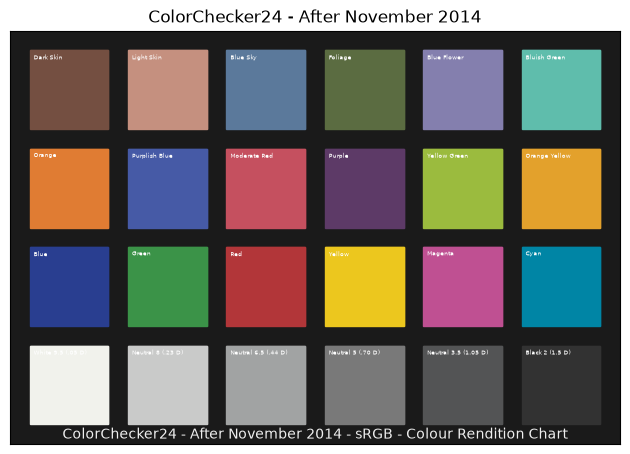

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'ColorChecker24 - After November 2014'}>)

In [81]:
#color checker grid
import colour
import numpy as np

# Load the ColorChecker object
cc = colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]

# cc.data contains the swatch values (usually as xyY values directly)
# Let's check what cc.data contains or pull the array values directly:
ref_xyY = np.array(list(cc.data.values()))

# Convert xyY to XYZ
ref_XYZ = colour.xyY_to_XYZ(ref_xyY)

print("Reference XYZ shape:", ref_XYZ.shape)  # Should be (24, 3)

import colour.plotting

# Plot the reference ColorChecker chart directly using the correct function name
colour.plotting.plot_single_colour_checker(
    "ColorChecker24 - After November 2014", text_kwargs={"visible": True, "fontsize": 4, "color": "white"}
)

In [82]:
#rotate my patches

# 1. Reshape your 24x3 table back into your 6x4 portrait grid shape
patch_grid_portrait = patch_means_table.reshape(6, 4, 3)

# 2. Rotate the grid 90 degrees clockwise (k=-1) to match landscape (4 rows x 6 cols)
patch_grid_landscape = np.rot90(patch_grid_portrait, k=-1)

# 3. Flatten back into a 24x3 reference-aligned table
patch_means_aligned = patch_grid_landscape.reshape(24, 3)

# --- PRINT AND VERIFY ---
print("==========================================================")
print("     ROTATED & ALIGNED 24 x 3 TABLE OF PATCH MEANS        ")
print("==========================================================")
for idx, rgb in enumerate(patch_means_aligned):
  print(
      f"Ref Patch {idx+1:2d} -> R: {rgb[0]:.6f} | G: {rgb[1]:.6f} |"
      f" B: {rgb[2]:.6f}"
  )

# Verify your white patch (which should now land on Ref Patch 19, index 18)
print(
    f"\nVerification - Ref Patch 19 (White) Max RGB Value:"
    f" {np.max(patch_means_aligned[18]):.6f}"
)

     ROTATED & ALIGNED 24 x 3 TABLE OF PATCH MEANS        
Ref Patch  1 -> R: 0.106749 | G: 0.087978 | B: 0.046204
Ref Patch  2 -> R: 0.338524 | G: 0.342013 | B: 0.188586
Ref Patch  3 -> R: 0.099217 | G: 0.214356 | B: 0.196037
Ref Patch  4 -> R: 0.078253 | G: 0.162524 | B: 0.073861
Ref Patch  5 -> R: 0.164054 | G: 0.271925 | B: 0.251433
Ref Patch  6 -> R: 0.179414 | G: 0.470868 | B: 0.303875
Ref Patch  7 -> R: 0.389742 | G: 0.244413 | B: 0.070603
Ref Patch  8 -> R: 0.077865 | G: 0.163579 | B: 0.225030
Ref Patch  9 -> R: 0.300148 | G: 0.217280 | B: 0.124339
Ref Patch 10 -> R: 0.069666 | G: 0.088218 | B: 0.091283
Ref Patch 11 -> R: 0.240988 | G: 0.544649 | B: 0.186277
Ref Patch 12 -> R: 0.373001 | G: 0.403569 | B: 0.122162
Ref Patch 13 -> R: 0.034496 | G: 0.066256 | B: 0.118411
Ref Patch 14 -> R: 0.097355 | G: 0.305956 | B: 0.124835
Ref Patch 15 -> R: 0.234016 | G: 0.142723 | B: 0.072429
Ref Patch 16 -> R: 0.456587 | G: 0.750872 | B: 0.219188
Ref Patch 17 -> R: 0.267729 | G: 0.231792 | B

In [83]:
#fit gains, normalize to green, and patch means after normalizing
import numpy as np

# 1. Select a mid-gray patch from the neutral row (Reference Patches 19-24)
# Reference Patch 21 corresponds to 0-indexed position 20 in your aligned table
neutral_ref_idx = 20  # Reference Patch 21 (Mid-Gray) index 20 in 0 index

ref_rgb = patch_means_aligned[neutral_ref_idx]
R_ref, G_ref, B_ref = ref_rgb

# 2. Calculate gains normalized to green
gain_r = G_ref / R_ref
gain_g = 1.0
gain_b = G_ref / B_ref

wb_gains = np.array([gain_r, gain_g, gain_b])

# 3. Apply the white balance gains to all 24 aligned patches
balanced_patch_means = patch_means_aligned * wb_gains

# --- DELIVERABLES OUTPUT ---
print("==================================================")
print("             QUESTION 5 DELIVERABLES              ")
print("==================================================")
print(f"Reference Neutral Patch Used: Ref Patch {neutral_ref_idx + 1}")
print(
    f"White Balance Gains (Normalized to Green):\n"
    f"  Red Gain   (g_R) : {wb_gains[0]:.6f}\n"
    f"  Green Gain (g_G) : {wb_gains[1]:.6f}\n"
    f"  Blue Gain  (g_B) : {wb_gains[2]:.6f}"
)
print("-" * 50)
print("Balanced Patch Means Table (24 x 3 Linear RGB):")
print("-" * 50)

for idx, rgb in enumerate(balanced_patch_means):
  print(
      f"Ref Patch {idx+1:2d} -> R: {rgb[0]:.6f} | G: {rgb[1]:.6f} |"
      f" B: {rgb[2]:.6f}"
  )

             QUESTION 5 DELIVERABLES              
Reference Neutral Patch Used: Ref Patch 21
White Balance Gains (Normalized to Green):
  Red Gain   (g_R) : 1.922127
  Green Gain (g_G) : 1.000000
  Blue Gain  (g_B) : 1.527195
--------------------------------------------------
Balanced Patch Means Table (24 x 3 Linear RGB):
--------------------------------------------------
Ref Patch  1 -> R: 0.205186 | G: 0.087978 | B: 0.070562
Ref Patch  2 -> R: 0.650685 | G: 0.342013 | B: 0.288007
Ref Patch  3 -> R: 0.190708 | G: 0.214356 | B: 0.299387
Ref Patch  4 -> R: 0.150413 | G: 0.162524 | B: 0.112800
Ref Patch  5 -> R: 0.315332 | G: 0.271925 | B: 0.383987
Ref Patch  6 -> R: 0.344856 | G: 0.470868 | B: 0.464077
Ref Patch  7 -> R: 0.749134 | G: 0.244413 | B: 0.107824
Ref Patch  8 -> R: 0.149666 | G: 0.163579 | B: 0.343665
Ref Patch  9 -> R: 0.576923 | G: 0.217280 | B: 0.189890
Ref Patch 10 -> R: 0.133906 | G: 0.088218 | B: 0.139407
Ref Patch 11 -> R: 0.463209 | G: 0.544649 | B: 0.284481
Ref Pat

In [84]:
#report error
import colour
import numpy as np

# 1. Convert balanced linear camera RGB to XYZ using standard sRGB primaries
xyz_measured = colour.sRGB_to_XYZ(balanced_patch_means)

# 2. Extract the measured white patch (Ref Patch 19 -> index 18) to use as the common white point
white_xy = colour.XYZ_to_xy(xyz_measured[18])

# 3. Load the ColorChecker reference object and convert xyY -> XYZ
cc = colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]
ref_xyY = np.array(list(cc.data.values()))
ref_XYZ = colour.xyY_to_XYZ(ref_xyY)

# 4. Convert BOTH measured and reference XYZ to CIELAB using the measured white patch as the illuminant
lab_measured = colour.XYZ_to_Lab(xyz_measured, illuminant=white_xy)
lab_reference = colour.XYZ_to_Lab(ref_XYZ, illuminant=white_xy)

# 5. Compute CIEDE2000 color difference across all 24 patches
delta_e_values = colour.delta_E(lab_measured, lab_reference, method="CIE 2000")

# 6. Extract Deliverables and identify the worst patch
mean_ae = np.mean(delta_e_values)
worst_ae = np.max(delta_e_values)
worst_idx = np.argmax(delta_e_values)

# Get patch names from the ColorChecker object keys
patch_names = list(cc.data.keys())
worst_patch_name = patch_names[worst_idx]

print("==================================================")
print("             QUESTION 6 DELIVERABLES              ")
print("==================================================")
print(f"Metric Name      : CIEDE2000 (ΔE00)")
print(f"Mean AE          : {mean_ae:.4f}")
print(f"Worst AE         : {worst_ae:.4f}")
print(f"Worst Patch      : Ref Patch {worst_idx + 1} ({worst_patch_name})")
print(f"White Point      : Measured Ref Patch 19 (Unclipped)")
print("--------------------------------------------------")

             QUESTION 6 DELIVERABLES              
Metric Name      : CIEDE2000 (ΔE00)
Mean AE          : 19.0705
Worst AE         : 25.1913
Worst Patch      : Ref Patch 14 (green)
White Point      : Measured Ref Patch 19 (Unclipped)
--------------------------------------------------


In [85]:
#matrix
import numpy as np

# 1. Solve least squares: balanced_patch_means (24x3) @ CCM.T = ref_XYZ (24x3)
# np.linalg.lstsq solves C * X = T, where X will be CCM.T (shape 3x3)
ccm_t, residuals, rank, s = np.linalg.lstsq(balanced_patch_means, ref_XYZ, rcond=None)
CCM = ccm_t.T  # Transpose back to get the 3x3 CCM

# 2. Compute row sums to evaluate neutral preservation
row_sums = np.sum(CCM, axis=1)

print("==================================================")
print("             QUESTION 7 DELIVERABLES              ")
print("==================================================")
print("Color Correction Matrix (CCM):")
print(CCM)
print("\nRow Sums:")
for i, r_sum in enumerate(row_sums):
    print(f"  Row {i+1} sum: {r_sum:.4f}")
print("--------------------------------------------------")

             QUESTION 7 DELIVERABLES              
Color Correction Matrix (CCM):
[[ 0.45802278  0.23268894  0.06475987]
 [ 0.16034012  0.6777807   0.0014217 ]
 [ 0.01602913 -0.40194738  1.09212814]]

Row Sums:
  Row 1 sum: 0.7555
  Row 2 sum: 0.8395
  Row 3 sum: 0.7062
--------------------------------------------------


             QUESTION 8 DELIVERABLES              
Metric Name          : CIEDE2000 (ΔE00)
Before Correction    : Mean AE = 19.0705, Worst AE = 25.1913
After Correction     : Mean AE = 5.2491, Worst AE = 12.4630
   CURRENT TOP 3 WORST PATCHES: BEFORE VS AFTER   
Patch                  | Before (ΔE00)  | After (ΔE00)
-------------------------------------------------------
Ref Patch 10 (purple)  | 16.9529        | 12.4630
Ref Patch 17 (magenta) | 15.9359        | 10.7797
Ref Patch 1 (dark skin) | 21.1563        | 8.5561
--------------------------------------------------


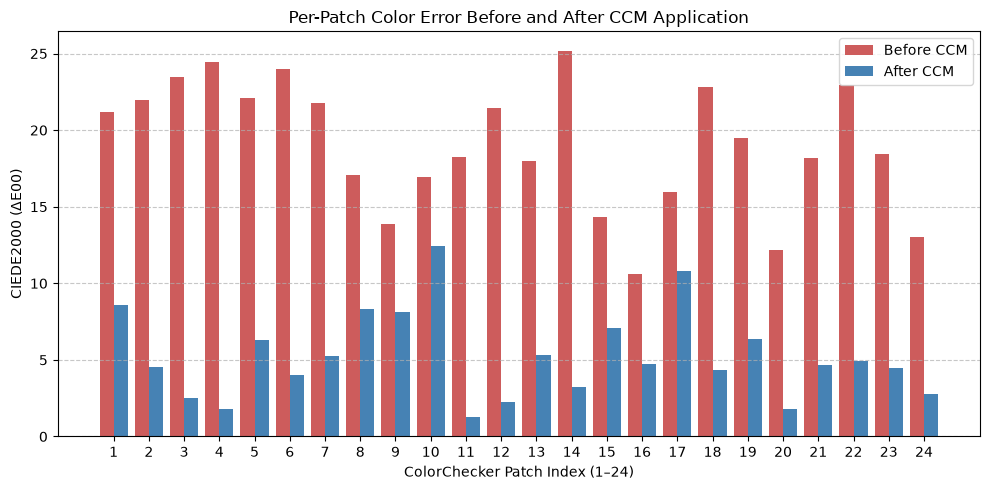

In [86]:
#apply matrix
import colour
import matplotlib.pyplot as plt
import numpy as np

# 1. Apply the CCM to the balanced patch means
# (Using ccm_t directly from your least-squares fit: balanced_patch_means @ ccm_t = ref_XYZ)
# If using CCM (3x3), it's balanced_patch_means @ CCM.T
xyz_corrected = balanced_patch_means @ ccm_t  # or balanced_patch_means @ CCM.T

# 2. Convert corrected XYZ to CIELAB using the measured white patch (Patch 19, index 18)
white_xy = colour.XYZ_to_xy(xyz_measured[18])
lab_corrected = colour.XYZ_to_Lab(xyz_corrected, illuminant=white_xy)

# 3. Re-calculate reference Lab using the same white point
cc = colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]
ref_xyY = np.array(list(cc.data.values()))
ref_XYZ = colour.xyY_to_XYZ(ref_xyY)
lab_reference = colour.XYZ_to_Lab(ref_XYZ, illuminant=white_xy)

# 4. Compute CIEDE2000 error before and after
delta_e_before = colour.delta_E(lab_measured, lab_reference, method="CIE 2000")
delta_e_after = colour.delta_E(lab_corrected, lab_reference, method="CIE 2000")

# 5. Extract Post-Correction Statistics
mean_ae_after = np.mean(delta_e_after)
worst_ae_after = np.max(delta_e_after)
worst_indices_after = np.argsort(delta_e_after)[-3:][::-1]  # Top 3 worst
patch_names = list(cc.data.keys())

print("==================================================")
print("             QUESTION 8 DELIVERABLES              ")
print("==================================================")
print(f"Metric Name          : CIEDE2000 (ΔE00)")
print(
    f"Before Correction    : Mean AE = {np.mean(delta_e_before):.4f}, Worst AE = {np.max(delta_e_before):.4f}"
)
print(
    f"After Correction     : Mean AE = {mean_ae_after:.4f}, Worst AE = {worst_ae_after:.4f}"
)

print("==================================================")
print("   CURRENT TOP 3 WORST PATCHES: BEFORE VS AFTER   ")
print("==================================================")
print(f"{'Patch':<22} | {'Before (ΔE00)':<14} | {'After (ΔE00)'}")
print("-" * 55)

for idx in worst_indices_after:
    p_name = f"Ref Patch {idx + 1} ({patch_names[idx]})"
    b_val = delta_e_before[idx]
    a_val = delta_e_after[idx]
    print(f"{p_name:<22} | {b_val:<14.4f} | {a_val:.4f}")

print("--------------------------------------------------")

# 6. Plot Per-Patch AE Before and After
plt.figure(figsize=(10, 5))
x = np.arange(1, 25)
plt.bar(
    x - 0.2, delta_e_before, width=0.4, label="Before CCM", color="indianred"
)
plt.bar(x + 0.2, delta_e_after, width=0.4, label="After CCM", color="steelblue")
plt.xlabel("ColorChecker Patch Index (1–24)")
plt.ylabel("CIEDE2000 (ΔE00)")
plt.title("Per-Patch Color Error Before and After CCM Application")
plt.xticks(x)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

**Part 3**

In [ ]:
#cosine similarity
import numpy as np

# 1. Input your three Color Correction Matrices from Question 9
ccm1 = np.array(
    [
        [0.45802278, 0.23268894, 0.06475987],
        [0.16034012, 0.67778070, 0.00142170],
        [0.01602913, -0.40194738, 1.09212814],
    ]
)

ccm2 = np.array(
    [
        [0.49559522, 0.23138613, 0.06880615],
        [0.20432992, 0.63702130, 0.03322836],
        [0.03589998, -0.42799155, 1.12447302],
    ]
)

ccm3 = np.array(
    [
        [0.58507629, 0.32081472, 0.02398096],
        [0.20804669, 0.86470779, -0.04200182],
        [0.01992148, -0.50450718, 1.35282622],
    ]
)

summary_rows = []


# 2. Function to compute math breakdown and save summary values
def analyze_column_directions(mat_a, mat_b, name_a, name_b):
  print(f"\n==================================================")
  print(f" MATH BREAKDOWN: {name_a} vs {name_b}")
  print(f"==================================================")

  channel_names = [
      "Col 1 (Red Map)",
      "Col 2 (Green Map)",
      "Col 3 (Blue Map)",
  ]
  sims = []

  for i in range(3):
    v1 = mat_a[:, i]
    v2 = mat_b[:, i]

    # Step A: Compute Vector Lengths (Norms)
    norm_v1 = np.linalg.norm(v1)
    norm_v2 = np.linalg.norm(v2)

    # Step B: Compute Dot Product
    dot_prod = np.dot(v1, v2)

    # Step C: Compute Cosine Similarity
    cos_sim = dot_prod / (norm_v1 * norm_v2)
    sims.append(cos_sim)

    print(f"--- {channel_names[i]} ---")
    print(
        f"  {name_a} vector : [{v1[0]:.4f}, {v1[1]:.4f}, {v1[2]:.4f}] (Norm:"
        f" {norm_v1:.4f})"
    )
    print(
        f"  {name_b} vector : [{v2[0]:.4f}, {v2[1]:.4f}, {v2[2]:.4f}] (Norm:"
        f" {norm_v2:.4f})"
    )
    print(f"  Dot Product    : {dot_prod:.6f}")
    print(f"  Cosine Similarity (v1 · v2 / ||v1|| ||v2||) : {cos_sim:.4f}")
    print()

  summary_rows.append((f"{name_a} vs. {name_b}", sims[0], sims[1], sims[2]))


# 3. Run detailed math for all pairs
analyze_column_directions(ccm1, ccm2, "Chart 1", "Chart 2")
analyze_column_directions(ccm1, ccm3, "Chart 1", "Chart 3")
analyze_column_directions(ccm2, ccm3, "Chart 2", "Chart 3")

# 4. Print Summary Table of Cosine Similarities
print("\n==========================================================")
print("     SUMMARY TABLE: COLUMN-WISE COSINE SIMILARITY        ")
print("==========================================================")
print(
    f"{'Comparison Pair':<20} | {'Col 1 (Red)':<12} | {'Col 2 (Green)':<12} |"
    f" {'Col 3 (Blue)':<12}"
)
print("-" * 65)

for pair_label, col1_sim, col2_sim, col3_sim in summary_rows:
  print(
      f"{pair_label:<20} | {col1_sim:<12.4f} | {col2_sim:<12.4f} |"
      f" {col3_sim:<12.4f}"
  )

print("----------------------------------------------------------")


 MATH BREAKDOWN: Chart 1 vs Chart 2
--- Col 1 (Red Map) ---
  Chart 1 vector : [0.4580, 0.1603, 0.0160] (Norm: 0.4855)
  Chart 2 vector : [0.4956, 0.2043, 0.0359] (Norm: 0.5373)
  Dot Product    : 0.260332
  Cosine Similarity (v1 · v2 / ||v1|| ||v2||) : 0.9980

--- Col 2 (Green Map) ---
  Chart 1 vector : [0.2327, 0.6778, -0.4019] (Norm: 0.8216)
  Chart 2 vector : [0.2314, 0.6370, -0.4280] (Norm: 0.8016)
  Dot Product    : 0.657632
  Cosine Similarity (v1 · v2 / ||v1|| ||v2||) : 0.9985

--- Col 3 (Blue Map) ---
  Chart 1 vector : [0.0648, 0.0014, 1.0921] (Norm: 1.0940)
  Chart 2 vector : [0.0688, 0.0332, 1.1245] (Norm: 1.1271)
  Dot Product    : 1.232572
  Cosine Similarity (v1 · v2 / ||v1|| ||v2||) : 0.9996


 MATH BREAKDOWN: Chart 1 vs Chart 3
--- Col 1 (Red Map) ---
  Chart 1 vector : [0.4580, 0.1603, 0.0160] (Norm: 0.4855)
  Chart 3 vector : [0.5851, 0.2080, 0.0199] (Norm: 0.6213)
  Dot Product    : 0.301656
  Cosine Similarity (v1 · v2 / ||v1|| ||v2||) : 1.0000

--- Col 2 (Green 

In [ ]:
#uncertainty
import numpy as np

# 1. Your three mean AE (CIEDE2000) values from the three independent charts
mean_delta_e_values = np.array([5.2491, 6.1466, 5.5945])

# 2. Compute the aggregate mean and sample standard deviation (uncertainty)
mean_ae = np.mean(mean_delta_e_values)
uncertainty = np.std(mean_delta_e_values, ddof=1)

print(f"Aggregate mean ΔE after correction : {mean_ae:.4f}")
print(f"Experimental Uncertainty : {uncertainty:.4f}")
print(f"Final Reported Value     : {mean_ae:.2f} ± {uncertainty:.2f}")

**Part 4**


Processing Outdoors Illuminant...

Processing Overhead Illuminant...

Processing LED Illuminant...

Processing Incandescent Illuminant...

  QUESTIONS 11 & 12 DELIVERABLES: MULTI-ILLUMINANT CARRY-OVER
Illuminant      | Mean ΔE00    | Worst ΔE00   | Worst Patch Name
-----------------------------------------------------------------
Outdoors        | 5.2491       | 12.4630      | Ref Patch 10 (purple)
Overhead        | 8.5506       | 25.0031      | Ref Patch 10 (purple)
LED             | 8.6516       | 11.2026      | Ref Patch 5 (blue flower)
Incandescent    | 8.4081       | 10.8868      | Ref Patch 14 (green)
-----------------------------------------------------------------


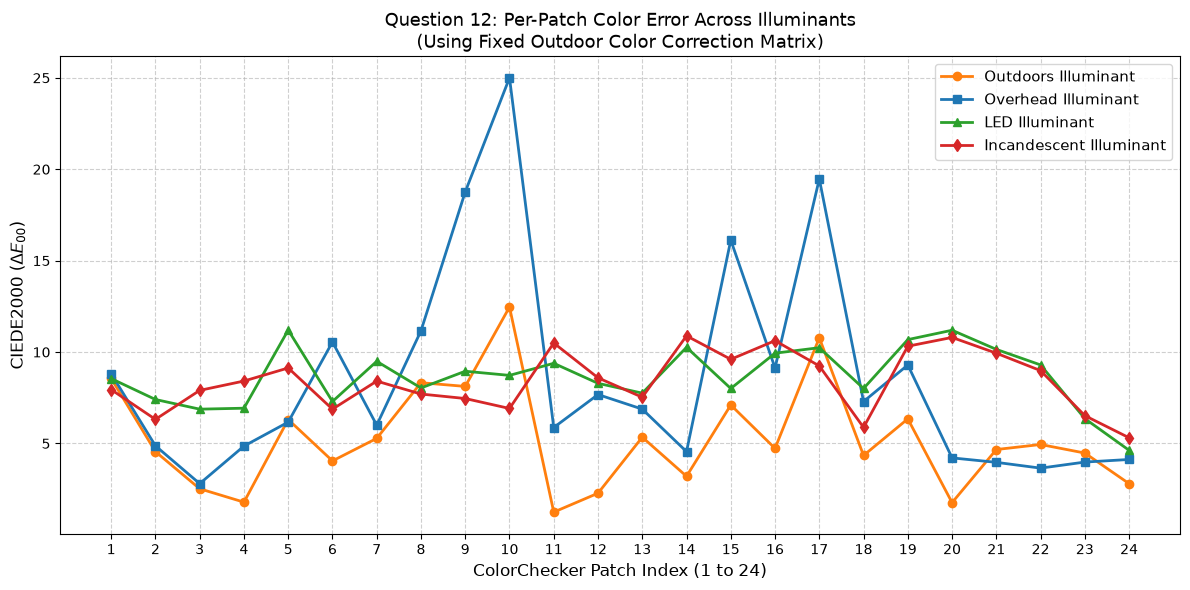

In [130]:
import colour
import matplotlib.pyplot as plt
import numpy as np

# ==============================================================================
# 1. FIXED OUTDOOR CCM & REFERENCE DATA SETUP
# ==============================================================================
ccm_item7 = np.array([
    [0.45802278, 0.23268894, 0.06475987],
    [0.16034012, 0.67778070, 0.00142170],
    [0.01602913, -0.40194738, 1.09212814],
])
ccm_t_item7 = ccm_item7.T

# Load reference ColorChecker dataset (ColorChecker24)
cc = colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]
ref_xyY = np.array(list(cc.data.values()))
ref_XYZ = colour.xyY_to_XYZ(ref_xyY)
patch_names = list(cc.data.keys())

# ==============================================================================
# 2. CAPTURE & WHITE SHEET METADATA
# ==============================================================================
illuminant_config = {
    "Outdoors": {
        "scene_file": "IMG_20261022_171022_1.dng",
        "scene_v_sat": 1023,
        "ws_file": "IMG_20261022_171048_0.dng",
        "ws_v_sat": 1020,
        "bbox": [490, 1510, 395, 1075],
    },
    "Overhead": {
        "scene_file": "IMG_20261022_171749_1.dng",
        "scene_v_sat": 1023,
        "ws_file": "IMG_20261022_171820_1.dng",
        "ws_v_sat": 1020,
        "bbox": [395, 1515, 395, 1120],
    },
    "LED": {
        "scene_file": "IMG_20261022_172057_0.dng",
        "scene_v_sat": 1023,
        "ws_file": "IMG_20261022_172115_1.dng",
        "ws_v_sat": 1023,
        "bbox": [480, 1500, 425, 1075],
    },
    "Incandescent": {
        "scene_file": "IMG_20261022_172506_0.dng",
        "scene_v_sat": 1023,
        "ws_file": "IMG_20261022_172524_1.dng",
        "ws_v_sat": 1023,
        "bbox": [500, 1515, 395, 1070],
    },
}


# ==============================================================================
# 3. HELPER FUNCTION: PREPROCESS & EXTRACT PATCH MEANS FOR A ROUND
# ==============================================================================
def process_round_patches(config):
  scene_rgb = process_raw_to_linear_rgb(
      f"../color_captures/{config['scene_file']}", config["scene_v_sat"]
  )
  ws_rgb = process_raw_to_linear_rgb(
      f"../color_captures/{config['ws_file']}", config["ws_v_sat"]
  )

  hh, ww, _ = scene_rgb.shape
  patch_size = 50
  r_c, c_c = hh // 2, ww // 2

  corrected_channels = []
  for i in range(3):
    scene_ch = scene_rgb[:, :, i]
    ws_ch = ws_rgb[:, :, i]

    ws_center_val = np.mean(
        ws_ch[
            r_c - patch_size // 2 : r_c + patch_size // 2,
            c_c - patch_size // 2 : c_c + patch_size // 2,
        ]
    )
    ws_ff_norm = ws_ch / ws_center_val
    corrected_ch = np.clip(scene_ch / ws_ff_norm, 0, 1)
    corrected_channels.append(corrected_ch)

  scene_corrected = np.stack(corrected_channels, axis=-1)

  raw_patch_means = extract_colorchecker_manual(
      scene_rgb=scene_corrected,
      grid_bbox=config["bbox"],
      inner_margin=0.25,
      visualize=False,
      title_suffix=config["scene_file"],
  )

  patch_grid_portrait = raw_patch_means.reshape(6, 4, 3)
  patch_grid_landscape = np.rot90(patch_grid_portrait, k=-1)
  aligned_patch_means = patch_grid_landscape.reshape(24, 3)

  return aligned_patch_means


# ==============================================================================
# 4. MAIN MULTI-ILLUMINANT ANALYSIS LOOP (QUESTIONS 11 & 12)
# ==============================================================================
results = {}
per_patch_errors = {}

for name, config in illuminant_config.items():
  print(f"\nProcessing {name} Illuminant...")

  # Step A: Extract aligned patch means
  aligned_means = process_round_patches(config)

  # Step B: Refit white balance gains using mid-gray neutral (Ref Patch 21 -> index 20)
  neutral_ref_idx = 20
  ref_rgb_val = aligned_means[neutral_ref_idx]
  gain_r = ref_rgb_val[1] / ref_rgb_val[0]
  gain_g = 1.0
  gain_b = ref_rgb_val[1] / ref_rgb_val[2]
  wb_gains = np.array([gain_r, gain_g, gain_b])

  balanced_means = aligned_means * wb_gains

  # Step C: Exposure scaling (BYPASSED for Outdoors, APPLIED for transfer illuminants)
  if name == "Outdoors":
    scaled_means = balanced_means  # No exposure scaling for native round
  else:
    exposure_scale = ref_XYZ[18, 1] / balanced_means[18, 1]
    scaled_means = balanced_means * exposure_scale

  # Step D: Apply matrix
  xyz_corrected = scaled_means @ ccm_t_item7

  # Step E: Convert to CIELAB using white point of this round's white patch (Ref Patch 19)
  xyz_measured_unscaled = colour.sRGB_to_XYZ(balanced_means)
  white_xy = colour.XYZ_to_xy(xyz_measured_unscaled[18])

  lab_corrected = colour.XYZ_to_Lab(xyz_corrected, illuminant=white_xy)
  lab_reference = colour.XYZ_to_Lab(ref_XYZ, illuminant=white_xy)

  # Step F: Compute CIEDE2000 color difference across all 24 patches
  delta_e = colour.delta_E(lab_corrected, lab_reference, method="CIE 2000")

  mean_ae = np.mean(delta_e)
  worst_ae = np.max(delta_e)
  worst_idx = np.argmax(delta_e)

  results[name] = {
      "mean_ae": mean_ae,
      "worst_ae": worst_ae,
      "worst_patch": f"Ref Patch {worst_idx + 1} ({patch_names[worst_idx]})",
  }
  per_patch_errors[name] = delta_e


# ==============================================================================
# 5. PRINT DELIVERABLES (QUESTIONS 11 & 12)
# ==============================================================================
print("\n" + "=" * 65)
print("  QUESTIONS 11 & 12 DELIVERABLES: MULTI-ILLUMINANT CARRY-OVER")
print("=" * 65)
print(
    f"{'Illuminant':<15} | {'Mean ΔE00':<12} | {'Worst ΔE00':<12} | Worst"
    " Patch Name"
)
print("-" * 65)

for name, res in results.items():
  print(
      f"{name:<15} | {res['mean_ae']:<12.4f} | {res['worst_ae']:<12.4f} |"
      f" {res['worst_patch']}"
  )

print("-" * 65)


# ==============================================================================
# 6. QUESTION 12 FIGURE: PER-PATCH ΔE ACROSS ALL ILLUMINANTS
# ==============================================================================
plt.figure(figsize=(12, 6))
x = np.arange(1, 25)

colors = {
    "Outdoors": "tab:orange",
    "Overhead": "tab:blue",
    "LED": "tab:green",
    "Incandescent": "tab:red",
}

markers = {"Outdoors": "o", "Overhead": "s", "LED": "^", "Incandescent": "d"}

for name, errors in per_patch_errors.items():
  plt.plot(
      x,
      errors,
      marker=markers[name],
      linestyle="-",
      color=colors[name],
      linewidth=2,
      label=f"{name} Illuminant",
  )

plt.xlabel("ColorChecker Patch Index (1 to 24)", fontsize=12)
plt.ylabel(r"CIEDE2000 ($\Delta E_{00}$)", fontsize=12)
plt.title(
    "Question 12: Per-Patch Color Error Across Illuminants\n(Using Fixed"
    " Outdoor Color Correction Matrix)",
    fontsize=13,
)
plt.xticks(x)
plt.legend(fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()